# 24 — Mean-energy và CVaR với khởi tạo INTERP

**Một input a3_dev_n5: 5 task + 3 host, 25 qubit.** Sau Notebook 23, giữ khởi tạo INTERP để kiểm tra ảnh hưởng objective. Domain-wall, penalty 4, X mixer, scaling và COBYLA giữ nguyên. Cả ba phương án huấn luyện exact; batch cuối 1024 shots chỉ chấm độc lập.

Mỗi phương án chạy mới p=1 mean-energy cap100, rồi INTERP sang p=2 cap100. Tại p=2 lần lượt tối ưu mean-energy, CVaR25% và CVaR10%. Tổng 3 kết quả, 6 lượt optimizer, tối đa600 đánh giá hàm. Không nhập góc đã học từ Notebook23. Bản bàn giao có output rỗng; QA không phải dữ liệu thí nghiệm chính. Đọc N24_README_FIRST.md.

## 1. Môi trường và cấu hình

Giữ mặc định để chạy toàn bộ. Nếu chỉ đo chi phí, PREPARE_ONLY=True; ghi lại CAMPAIGN_DIR và resume lần sau để tránh tạo campaign mới. MAX_NEW_TRIALS tính lượt optimizer, không phải số phương án.

In [1]:
from pathlib import Path
import sys
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'src/cvar_campaign.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Chép đủ gói Notebook24 vào thư mục gốc repo.')
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))
from src.cvar_campaign import (PROTOCOL, load_json, identity, make_plan,
    create_campaign, prepare_campaign, run_campaign, summarize, export_campaign)

RESUME_DIR = None
MAX_NEW_TRIALS = None
TARGET_GROUPS = None  # Ví dụ ['p2__cvar_025']; kế hoạch vẫn giữ đủ ba nhóm.
PREPARE_ONLY = False
print('Python:',sys.executable)
print('Repo:',ROOT)

Python: c:\Users\Khiem\anaconda3\envs\nt409-khiem\python.exe
Repo: c:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement


## 2. Kế hoạch và ý nghĩa CVaR

| Nhóm | p=1 chuẩn bị | p=2 đích | Tổng cap |
|---|---|---|---:|
| p2__mean | Mean, 100 | Mean, 100 | 200 |
| p2__cvar_025 | Mean, 100 | CVaR alpha=0.25, 100 | 200 |
| p2__cvar_010 | Mean, 100 | CVaR alpha=0.10, 100 | 200 |

CVaR25% là năng lượng trung bình của **25% khối xác suất có năng lượng thấp nhất**, không phải 25% số bitstring. Nếu mức năng lượng tại biên làm vượt alpha, chỉ lấy đủ phần xác suất tại mức đó. Alpha=1 chính là mean. Hàm lower_tail_cvar được tái sử dụng từ Notebook14, còn evaluator dùng mạch ba host25 qubit hiện tại.

Mỗi nhóm có p=1 mới theo cùng objective/điểm/cap để thu cùng khởi tạo p=2; chỉ objective p=2 thay đổi. INTERP: [beta,gamma] → [beta,beta,gamma,gamma]. Không tối ưu p=1 bằng CVaR ở bước này, vì như vậy sẽ đồng thời đổi điểm khởi tạo. Nfev thực tế có thể ít hơn cap. Hai alpha được cố định trước campaign; không chọn alpha sau khi xem P_opt.

In [2]:
protocol = load_json(ROOT/PROTOCOL)
ident = identity(ROOT,protocol)
plan = make_plan(protocol)
instance = next(iter(ident['inputs'].values()))
display(pd.DataFrame(instance['tasks']))
display(pd.DataFrame(instance['hosts']))
print('Model:',ident['model'])
print('Runtime:',ident['runtime'])
print('software_validation:',protocol['software_validation'])
display(pd.DataFrame([dict(id=t['id'],group=t['group'],p=t['p'],alpha=t['alpha'],
    cap=t['config']['maxiter'],initial_point=t['config']['initial_point'],
    depends_on=t['depends_on']) for t in plan]))
print('Groups:',len(set(t['group'] for t in plan)),'| optimizer trials:',len(plan))
print('Tổng trần đánh giá:',sum(t['config']['maxiter'] for t in plan))

,id,cpu,ram
0,t0,1,1
1,t1,1,1
2,t2,1,1
3,t3,1,1
4,t4,1,2


,id,cpu,ram
0,h0,2,2
1,h1,3,3
2,h2,3,3


Model: {'qubits': 25, 'scale': 65.5}
Runtime: {'python_version': '3.12.14', 'platform': 'Windows-11-10.0.26200-SP0', 'numpy_version': '2.5.3', 'scipy_version': '1.18.1', 'qiskit_version': '2.5.2', 'qiskit_optimization_version': '0.7.0', 'qiskit_aer_version': '0.17.2'}
software_validation: False


,id,group,p,alpha,cap,initial_point,depends_on
0,p2__mean__stage1,p2__mean,1,1.00,100,"[0.3, 1.0]",NaN
1,p2__mean__stage2,p2__mean,2,1.00,100,None,p2__mean__stage1
2,p2__cvar_025__stage1,p2__cvar_025,1,1.00,100,"[0.3, 1.0]",NaN
3,p2__cvar_025__stage2,p2__cvar_025,2,0.25,100,None,p2__cvar_025__stage1
4,p2__cvar_010__stage1,p2__cvar_010,1,1.00,100,"[0.3, 1.0]",NaN
5,p2__cvar_010__stage2,p2__cvar_010,2,0.10,100,None,p2__cvar_010__stage1


Groups: 3 | optimizer trials: 6
Tổng trần đánh giá: 600


## 3. Kiểm thử trước chạy

Chạy tám test mới bằng Python của kernel: boundary CVaR, histogram so với phép tính từng trạng thái, mean-control so với code cũ, kế toán ngân sách, INTERP có tính phí, partial/resume, giữ lỗi và audit chống sửa số. Fixture nhỏ nằm trong thư mục tạm; không thuộc dữ liệu nghiên cứu.

In [3]:
check = subprocess.run([sys.executable,'-m','unittest','discover','-s','tests',
    '-p','test_cvar_campaign.py'],cwd=ROOT,text=True,capture_output=True)
print(check.stdout)
print(check.stderr)
check.check_returncode()


.c:\Users\Khiem\anaconda3\envs\nt409-khiem\Lib\site-packages\qiskit\circuit\library\n_local\evolved_operator_ansatz.py:324: DeprecationWarning: The class ``qiskit.circuit.library.n_local.n_local.NLocal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. This applies to NLocal subclasses too. Use the corresponding function from the module qiskit.circuit.library.n_local instead.
  super().__init__(
c:\Users\Khiem\anaconda3\envs\nt409-khiem\Lib\site-packages\qiskit\circuit\library\n_local\n_local.py:379: DeprecationWarning: The class ``qiskit.circuit.library.blueprintcircuit.BlueprintCircuit`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. There is no direct replacement other than the QuantumCircuit class.
  super().__init__(name=name)
.......
----------------------------------------------------------------------
Ran 8 tests in 4.164s

OK



## 4. Tạo hoặc tiếp tục campaign

Mỗi lần RESUME_DIR=None tạo campaign mới. Giữ nguyên input, protocol, nguồn và runtime khi resume. Không trỏ đến campaign init_ của Notebook23. Lượt đã hoàn tất không chạy lại.

In [4]:
CAMPAIGN_DIR = create_campaign(ROOT,output=RESUME_DIR,protocol=protocol)
print('CAMPAIGN_DIR =',str(CAMPAIGN_DIR))
print('Lần sau đặt RESUME_DIR =',repr(str(CAMPAIGN_DIR)))
display(pd.DataFrame([summarize(CAMPAIGN_DIR)['coverage']]))

CAMPAIGN_DIR = C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4p_cvar\cvar_20261024T033340873038Z
Lần sau đặt RESUME_DIR = 'C:\\Users\\Khiem\\quang-tum-com-pu-ting\\nt409-task-placement\\data\\reference_results\\phase4p_cvar\\cvar_20261024T033340873038Z'


,planned,completed,failed,pending
0,3,0,0,3


## 5. Đo chi phí

Profile một exact/batch đo ở mỗi độ sâu; ở p=2 đo thêm phép tính CVaR25% và CVaR10%. Histogram gộp cùng mức năng lượng; không sắp xếp 2**25 trạng thái ở mỗi evaluation. Profiling không cập nhật góc huấn luyện.

Ước lượng giả sử dùng hết cap với tốc độ góc profile, chưa gồm khởi tạo, chấm cuối và audit. Đây là so sánh cùng trần số đánh giá hàm; không cam kết cùng thời gian/backend calls. Các chi phí chấm được ghi riêng, và CVaR có thêm chi phí histogram.

In [5]:
costs = prepare_campaign(ROOT,CAMPAIGN_DIR,progress=True)
display(pd.DataFrame(costs['profiles']))
display(pd.DataFrame(costs['strategies']))
print('Ước lượng giờ huấn luyện toàn bộ nếu dùng hết cap:',
      round(sum(r['training_cap_hours'] for r in costs['strategies']),2))

Profile depth 1
  calibration 1/1: 3.59s
Profile depth 2
  calibration 1/1: 6.28s


,p,qubits,objective_seconds,measurement_seconds
0,1,25,{'1.0': 4.005715599999348},3.589396
1,2,25,"{'1.0': 5.9604269999999815, '0.25': 5.78552589...",6.279366


,group,cap,training_cap_hours
0,p2__mean,200,0.276837
1,p2__cvar_025,200,0.271979
2,p2__cvar_010,200,0.269935


Ước lượng giờ huấn luyện toàn bộ nếu dùng hết cap: 0.82


## 6. Huấn luyện exact tuần tự

Mỗi lượt có guard7200 giây và RAM khả dụng tối thiểu4 GiB, kiểm tra giữa các lời gọi native, không phải ngắt cứng. Lịch sử lưu mean_energy và raw_objective riêng. Alpha<1: raw_objective là CVaR; không gọi nó là mean.

Lượt được ghi nhận running trước khi bắt đầu. Khi lỗi/ngắt: giữ raw report và traceback; không tự retry/reset ngân sách. Có thể resume nhóm khác còn lành mạnh bằng TARGET_GROUPS. Chỉ xóa RUNNING.lock khi chắc tiến trình cũ đã dừng. Không để máy sleep trong lúc chạy.

In [6]:
if PREPARE_ONLY:
    print('Chỉ đo chi phí; ghi lại CAMPAIGN_DIR để resume.')
    state = summarize(CAMPAIGN_DIR)
else:
    state = run_campaign(ROOT,CAMPAIGN_DIR,max_new_trials=MAX_NEW_TRIALS,
                         groups=TARGET_GROUPS,progress=True)
print(state['status'],state['coverage'])
if state['coverage']['failed']:
    print('Có nhóm chưa hoàn tất; giữ traceback và bản ghi, chưa kết luận nhóm đó.')

Run p2__mean__stage1 | alpha 1.0 | cap 100
  alpha=1 eval 1: objective=548.977473; E=548.977473
  alpha=1 eval 25: objective=224.237281; E=224.237281
  alpha=1 eval 50: objective=196.022445; E=196.022445
  alpha=1 eval 75: objective=108.727684; E=108.727684
  alpha=1 eval 100: objective=104.940713; E=104.940713
Run p2__mean__stage2 | alpha 1.0 | cap 100
  alpha=1 eval 1: objective=115.277799; E=115.277799
  alpha=1 eval 25: objective=66.838697; E=66.838697
  alpha=1 eval 50: objective=65.158936; E=65.158936
  alpha=1 eval 75: objective=63.416669; E=63.416669
  alpha=1 eval 100: objective=62.836536; E=62.836536
Run p2__cvar_025__stage1 | alpha 1.0 | cap 100
  alpha=1 eval 1: objective=548.977473; E=548.977473
  alpha=1 eval 25: objective=224.237281; E=224.237281
  alpha=1 eval 50: objective=196.022445; E=196.022445
  alpha=1 eval 75: objective=108.727684; E=108.727684
  alpha=1 eval 100: objective=104.940713; E=104.940713
Run p2__cvar_025__stage2 | alpha 0.25 | cap 100
  alpha=0.25 eval

## 7. Chấm và so sánh

Mỗi dòng là một phương án, chỉ dùng góc p=2 trả về theo objective của phương án đó. Không chọn góc theo P_opt hoặc chọn lại điểm đẹp trong history. Nfev bao gồm p=1 chuẩn bị. Không xem sáu lượt là sáu mẫu độc lập.

P_opt/P_valid/P_ground là xác suất exact trên toàn phân phối, không điều kiện hóa hoặc sửa bit. Mỗi endpoint được chấm mean, CVaR25% và CVaR10%: chỉ so sánh số trong **cùng một cột objective** giữa các phương án, không so raw CVaR10% với raw mean rồi kết luận thắng.

P_opt tăng mới hỗ trợ mục tiêu tăng xác suất placement tối ưu. Tối ưu CVaR của QUBO (gồm slack/penalty) không bảo đảm P_opt tăng. Optimal_count là một batch1024 shots; không dùng chênh lệch nhỏ của counts thay cho xác suất exact. Mỗi phương án xác định có một kết quả; không tạo SD/khoảng tin cậy từ lặp giống nhau.

In [7]:
summary = summarize(CAMPAIGN_DIR)
results = pd.DataFrame(summary['rows'])
print(summary['status'],summary['coverage'])
display(results)
metrics = ['group','objective_alpha','mean_energy','cvar_025','cvar_010',
           'p_opt','p_valid','p_ground','nfev','budget_cap','seconds']
display(results[[k for k in metrics if k in results.columns]])
done = results[results['status'].eq('completed')]
if 'p2__mean' in set(done['group']):
    base = done.set_index('group').loc['p2__mean']
    if base['p_opt'] > 0:
        display(pd.DataFrame([dict(group=r['group'],
            p_opt_gain_relative_percent=100*(r['p_opt']/base['p_opt']-1),
            p_opt_gain_percentage_points=100*(r['p_opt']-base['p_opt']))
            for r in done.to_dict('records')]))

complete {'planned': 3, 'completed': 3, 'failed': 0, 'pending': 0}


,group,objective_alpha,trials_completed,status,budget_cap,nfev,diagnostic_exact_calls,final_measurement_shots,selected_trial,selected_point,mean_energy,cvar_025,cvar_010,raw_objective,p_opt,p_valid,p_ground,optimal_count,seconds
0,p2__mean,1.00,2,completed,200,200,4,2048,p2__mean__stage2,"[2.665266451485739, 2.872341303436726, 0.53711...",62.823613,22.525428,15.850448,62.823613,0.008361,0.163361,0.000031,5,1041.907965
1,p2__cvar_025,0.25,2,completed,200,200,4,2048,p2__cvar_025__stage2,"[2.693436496138451, 2.8625881898289576, 0.7318...",70.154597,21.792483,15.332956,21.792483,0.007830,0.150794,0.000057,9,1095.009775
2,p2__cvar_010,0.10,2,completed,200,200,4,2048,p2__cvar_010__stage2,"[2.7205262384903177, 2.8640951957928213, 0.802...",75.533310,21.933221,15.299829,15.299829,0.008181,0.139316,0.000068,9,4085.766138


,group,objective_alpha,mean_energy,cvar_025,cvar_010,p_opt,p_valid,p_ground,nfev,budget_cap,seconds
0,p2__mean,1.00,62.823613,22.525428,15.850448,0.008361,0.163361,0.000031,200,200,1041.907965
1,p2__cvar_025,0.25,70.154597,21.792483,15.332956,0.007830,0.150794,0.000057,200,200,1095.009775
2,p2__cvar_010,0.10,75.533310,21.933221,15.299829,0.008181,0.139316,0.000068,200,200,4085.766138


,group,p_opt_gain_relative_percent,p_opt_gain_percentage_points
0,p2__mean,0.000000,0.000000
1,p2__cvar_025,-6.346426,-0.053063
2,p2__cvar_010,-2.157488,-0.018039


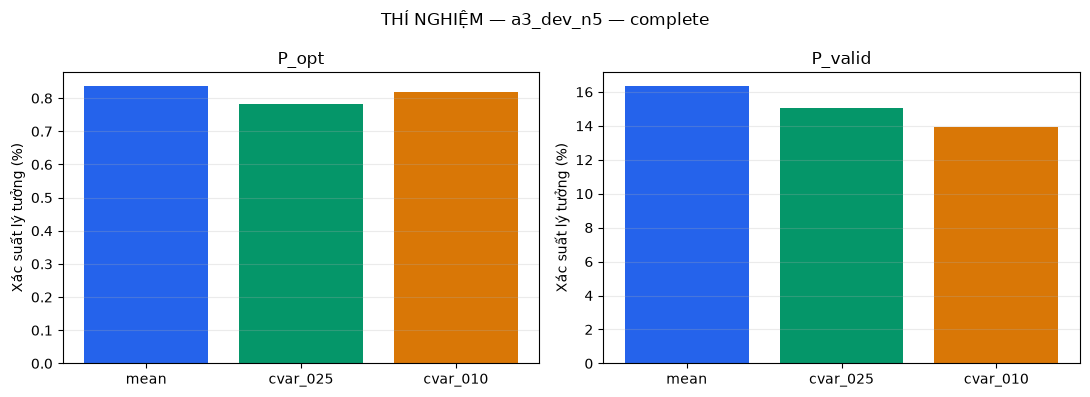

In [8]:
if done.empty:
    print('Chưa có phương án hoàn tất để vẽ.')
else:
    fig,axes = plt.subplots(1,2,figsize=(11,4))
    labels = done['group'].str.replace('p2__','',regex=False)
    for ax,key,title in zip(axes,['p_opt','p_valid'],['P_opt','P_valid']):
        ax.bar(labels,100*done[key],color=['#2563eb','#059669','#d97706'][:len(done)])
        ax.set_ylabel('Xác suất lý tưởng (%)')
        ax.set_title(title)
        ax.set_ylim(bottom=0)
        ax.grid(axis='y',alpha=.25)
    label = 'KIỂM THỬ PHẦN MỀM' if summary['software_validation'] else 'THÍ NGHIỆM'
    fig.suptitle(label+' — a3_dev_n5 — '+summary['status'])
    fig.tight_layout()
    fig.savefig(CAMPAIGN_DIR/'cvar_quality.png',dpi=160)
    plt.show()

## 8. Audit và xuất kết quả

Audit kiểm hashes, protocol, cùng khởi tạo p=2, parent INTERP, ngân sách từng giai đoạn/tổng, phân biệt mean/CVaR và final counts; tính lại endpoint và CVaR. Có thể mất thêm thời gian. Không replay mọi evaluation trong history.

PASS xác nhận nhất quán; complete=True xác nhận đủ ba phương án/sáu lượt. Không giá trị nào chứng minh chất lượng đã tăng. Lưu notebook có output và gửi cùng cvar_<timestamp>.zip. Kết quả chỉ áp dụng cho input đã dùng để chọn INTERP; đọc docs/notebook24_cvar_vi.md trước kết luận.

In [9]:
RESULT_ZIP = export_campaign(ROOT,CAMPAIGN_DIR)
audit = load_json(CAMPAIGN_DIR/'audit.json')
print('audit:',audit['status'],'| complete:',audit['complete'])
print('coverage:',audit['coverage'],'| common_p2_start:',audit['common_p2_start'])
print('Gửi file ZIP:',RESULT_ZIP)
if not audit['complete']:
    print('Kế hoạch còn partial; chưa kết luận từ tập nhóm chưa đủ.')

audit: PASS | complete: True
coverage: {'planned': 3, 'completed': 3, 'failed': 0, 'pending': 0} | common_p2_start: True
Gửi file ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4p_cvar\cvar_20261024T033340873038Z.zip
